# TP Final · 02 · Modelos, comparación y lectura de negocio

Se entrenan **tres algoritmos** sobre las mismas variables, la misma partición train / test y con la misma métrica principal (**PR-AUC en test**). Cada entrenamiento queda registrado como un run de MLflow. Después se elige el mejor y se interpreta qué significa para el negocio.

| Sección | Qué se hace |
|---|---|
| 1 | Datos y variables |
| 2 | Los tres modelos |
| 3 | Entrenamiento y registro en MLflow |
| 4 | Comparación y elección |
| 5 | Lectura de negocio del modelo elegido: deciles de riesgo, umbral e importancia de variables |

In [0]:
dbutils.widgets.text("student_id", "tfernandezaddoumie", "01 - Identificador")

In [0]:
import warnings
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
warnings.filterwarnings("ignore")

student_id = dbutils.widgets.get("student_id")
catalog = spark.sql("SELECT current_catalog()").first()[0]
table = f"{catalog}.bigdata_{student_id}.tp_credit_default"
data_version = spark.sql(f"DESCRIBE HISTORY {table}").agg({"version": "max"}).first()[0]

user = spark.sql("SELECT current_user()").first()[0]
experiment = mlflow.set_experiment(f"/Users/{user}/bigdata_{student_id}_tp_final")
mlflow.autolog(disable=True)

data = spark.table(table).toPandas()
print("Experimento:", experiment.name)
print(f"Tabla: {table} (versión Delta {data_version}) · {len(data):,} filas")

{"ts": "2026-11-01 01:09:53.174", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chhub3RlYm9va3MvNTUxMTAzMDI3MTM0MjEQASABMiQwMWExOTRhNy05MGUyLTdmNzMtYmU2YS1mZGJiNTBhMTY0Njc6JGU2YmIyMDUwLTY4ZWYtMzQxNy1iMjBmLTY3YWE1YjlhNWM1M0oKCMyimtcGEICJelABWAFgAWjbybyu7cSjDYgBAA==.", "context": {}}
{"ts": "2026-11-01 01:09:53.174", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chhub3RlYm9va3MvNTUxMTAzMDI3MTM0MjEQASABMiQwMWExOTRhNy05MGUyLTdmNzMtYmU2YS1mZGJiNTBhMTY0Njc6JGU2YmIyMDUwLTY4ZWYtMzQxNy1iMjBmLTY3YWE1YjlhNWM1M0oKCMyimtcGEICJelABWAFgAWjbybyu7cSjDYgBAA==.", "context": {}}
{"ts": "2026-11-01 01:09:53.174", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chhub3RlYm9va3MvNTUxMTAzMDI3MTM0MjEQASABMiQwMWExOTRhNy05MGUyLTdmNzMtYmU2YS1mZGJiNTBhMTY0Njc6JGU2YmIyMDUwLTY4ZWYtMzQxNy1iMjBmLTY3YWE1YjlhNWM1M0oK

Experimento: /Users/tfernandezaddoumie@itba.edu.ar/bigdata_tfernandezaddoumie_tp_final
Tabla: workspace.bigdata_tfernandezaddoumie.tp_credit_default (versión Delta 0) · 30,000 filas


## 1. Datos y variables

Se usan las 23 variables del dataset. Las tres categóricas (`sex`, `education`, `marriage`) se transforman en columnas 0/1 (*one-hot*); las numéricas se estandarizan para que la regresión logística no dependa de la escala de cada una (montos de cientos de miles contra estados de pago de -2 a 8).

In [0]:
LABEL = "default_next_month"
CATEGORICAL = ["sex", "education", "marriage"]
NUMERIC = (["limit_bal", "age"]
           + [f"pay_{i}" for i in range(1, 7)]
           + [f"bill_amt{i}" for i in range(1, 7)]
           + [f"pay_amt{i}" for i in range(1, 7)])
FEATURES = NUMERIC + CATEGORICAL

data[CATEGORICAL] = data[CATEGORICAL].astype(str)
data[NUMERIC] = data[NUMERIC].astype("float64")
train = data[data["split"] == "train"].sort_values("id").reset_index(drop=True)
test = data[data["split"] == "test"].sort_values("id").reset_index(drop=True)
X_train, y_train = train[FEATURES], train[LABEL]
X_test, y_test = test[FEATURES], test[LABEL]
base_rate = y_test.mean()

print(f"{len(FEATURES)} variables")
print(f"train: {len(train):,} clientes · {y_train.mean():.1%} en mora")
print(f"test:  {len(test):,} clientes · {base_rate:.1%} en mora")

23 variables
train: 24,021 clientes · 22.3% en mora
test:  5,979 clientes · 21.3% en mora


## 2. Los tres modelos

| Modelo | Cómo decide | Hiperparámetros |
|---|---|---|
| Regresión logística | Suma ponderada de las variables: cada variable empuja el riesgo hacia arriba o hacia abajo | `C = 1.0` |
| Random forest | 200 árboles de decisión independientes que votan | `n_estimators = 200`, `max_depth = 8` |
| Gradient boosting | Árboles en secuencia: cada uno corrige los errores del anterior | `learning_rate = 0.1`, `max_depth = 5`, `max_iter = 150` |

La profundidad de los árboles se limita para evitar el sobreajuste. Cada modelo se arma como un *pipeline* (preprocesamiento + modelo) y se registra entero en MLflow.

In [0]:
def preprocesamiento():
    return ColumnTransformer([("num", StandardScaler(), NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])

MODELOS = {
    "regresion_logistica": (LogisticRegression(C=1.0, max_iter=1000),
                            {"C": 1.0}),
    "random_forest": (RandomForestClassifier(n_estimators=200, max_depth=8, n_jobs=-1, random_state=42),
                      {"n_estimators": 200, "max_depth": 8}),
    "gradient_boosting": (HistGradientBoostingClassifier(learning_rate=0.1, max_depth=5, max_iter=150, random_state=42),
                          {"learning_rate": 0.1, "max_depth": 5, "max_iter": 150}),
}
UMBRAL = 0.5   # probabilidad desde la cual el modelo marca a un cliente como "en riesgo"

## 3. Entrenamiento y registro en MLflow

Por cada modelo se abre un run y se registra:

- **Parámetros:** modelo, hiperparámetros, umbral, tabla y versión Delta de los datos, cantidad de filas.
- **Métricas en test:** PR-AUC (principal), ROC-AUC, accuracy, precision, recall y F1 con el umbral 0,5, y PR-AUC en train para detectar sobreajuste.
- **Artefactos:** matriz de confusión, curva precision-recall y el modelo entrenado con su firma.

In [0]:
def metricas(y, scores, umbral):
    pred = (scores >= umbral).astype(int)
    return {"test_pr_auc": average_precision_score(y, scores),
            "test_roc_auc": roc_auc_score(y, scores),
            "test_accuracy": accuracy_score(y, pred),
            "test_precision": precision_score(y, pred, zero_division=0),
            "test_recall": recall_score(y, pred, zero_division=0),
            "test_f1": f1_score(y, pred, zero_division=0),
            "test_alertas": int(pred.sum())}

def figura_matriz(y, scores, umbral, titulo):
    matriz = confusion_matrix(y, (scores >= umbral).astype(int), labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(matriz, cmap="Blues")
    for (i, j), valor in np.ndenumerate(matriz):
        ax.text(j, i, f"{valor:,}", ha="center", va="center",
                color="white" if valor > matriz.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["sin alerta", "alerta"])
    ax.set_yticks([0, 1], ["pagó", "mora"])
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Realidad")
    ax.set_title(titulo, fontsize=10)
    fig.tight_layout()
    return fig

def figura_curva_pr(y, scores, titulo):
    precision, recall, _ = precision_recall_curve(y, scores)
    fig, ax = plt.subplots(figsize=(4.8, 3.6))
    ax.plot(recall, precision, color="#2563eb")
    ax.axhline(y.mean(), color="#94a3b8", ls="--", label=f"azar = {y.mean():.3f}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(titulo, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig

def registrar_modelo(pipeline, X_ejemplo):
    firma = infer_signature(X_ejemplo, pipeline.predict(X_ejemplo))
    kwargs = dict(sk_model=pipeline, signature=firma, input_example=X_ejemplo.head(5),
                  serialization_format="cloudpickle")
    if int(mlflow.__version__.split(".")[0]) >= 3:
        mlflow.sklearn.log_model(name="model", **kwargs)
    else:
        mlflow.sklearn.log_model(artifact_path="model", **kwargs)

In [0]:
resultados = {}
for nombre, (modelo, hiperparametros) in MODELOS.items():
    pipeline = Pipeline([("preprocesamiento", preprocesamiento()), ("modelo", modelo)])
    with mlflow.start_run(run_name=nombre, tags={"tp": "final", "student_id": student_id}) as run:
        mlflow.log_params({"modelo": nombre, **hiperparametros, "umbral": UMBRAL, "n_features": len(FEATURES),
                           "train_rows": len(train), "test_rows": len(test),
                           "data_table": table, "data_version": data_version})
        pipeline.fit(X_train, y_train)
        scores_train = pipeline.predict_proba(X_train)[:, 1]
        scores_test = pipeline.predict_proba(X_test)[:, 1]

        m = {**metricas(y_test, scores_test, UMBRAL), "train_pr_auc": average_precision_score(y_train, scores_train)}
        mlflow.log_metrics(m)
        mlflow.log_figure(figura_matriz(y_test, scores_test, UMBRAL, nombre), "matriz_confusion.png")
        mlflow.log_figure(figura_curva_pr(y_test, scores_test, nombre), "curva_precision_recall.png")
        registrar_modelo(pipeline, X_test)
        plt.close("all")

    resultados[nombre] = {"run_id": run.info.run_id, "pipeline": pipeline, "scores_test": scores_test}
    print(f"{nombre:<20} PR-AUC test {m['test_pr_auc']:.3f} · train {m['train_pr_auc']:.3f} · "
          f"precision {m['test_precision']:.3f} · recall {m['test_recall']:.3f}")

🔗 View Logged Model at: https://dbc-5f1661b8-eb1e.cloud.databricks.com/ml/experiments/3911777452282939/models/m-6b979212d82d47f1842cddd97c14b55a?o=7474646841500891


regresion_logistica  PR-AUC test 0.487 · train 0.511 · precision 0.703 · recall 0.241


🔗 View Logged Model at: https://dbc-5f1661b8-eb1e.cloud.databricks.com/ml/experiments/3911777452282939/models/m-02c6c0cf7fa74144b50d09b76c79409a?o=7474646841500891


random_forest        PR-AUC test 0.544 · train 0.648 · precision 0.670 · recall 0.351


🔗 View Logged Model at: https://dbc-5f1661b8-eb1e.cloud.databricks.com/ml/experiments/3911777452282939/models/m-339993a53ff949faa7cdf9d54475418b?o=7474646841500891


gradient_boosting    PR-AUC test 0.550 · train 0.628 · precision 0.664 · recall 0.355


## 4. Comparación y elección

Los runs se leen desde MLflow con `search_runs`, que devuelve el experimento como una tabla. Si el notebook se ejecutó más de una vez, se toma el run más reciente de cada modelo.

In [0]:
runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id],
                          filter_string=f"tags.tp = 'final' AND tags.student_id = '{student_id}'",
                          order_by=["start_time DESC"])
columnas = {"tags.mlflow.runName": "modelo", "metrics.test_pr_auc": "pr_auc", "metrics.train_pr_auc": "train_pr_auc",
            "metrics.test_roc_auc": "roc_auc", "metrics.test_accuracy": "accuracy",
            "metrics.test_precision": "precision", "metrics.test_recall": "recall", "metrics.test_f1": "f1",
            "metrics.test_alertas": "alertas", "run_id": "run_id"}
comparacion = (runs[list(columnas)].rename(columns=columnas)
               .drop_duplicates("modelo").sort_values("pr_auc", ascending=False).reset_index(drop=True))
display(comparacion.drop(columns="run_id").round(3))
print(f"Referencia: un modelo al azar tiene PR-AUC ≈ {base_rate:.3f}; "
      f"decir siempre 'paga' tiene accuracy {1 - base_rate:.3f}.")

modelo,pr_auc,train_pr_auc,roc_auc,accuracy,precision,recall,f1,alertas
gradient_boosting,0.55,0.628,0.782,0.824,0.664,0.355,0.462,681.0
random_forest,0.544,0.648,0.78,0.825,0.67,0.351,0.461,667.0
regresion_logistica,0.487,0.511,0.721,0.817,0.703,0.241,0.359,437.0


Referencia: un modelo al azar tiene PR-AUC ≈ 0.213; decir siempre 'paga' tiene accuracy 0.787.


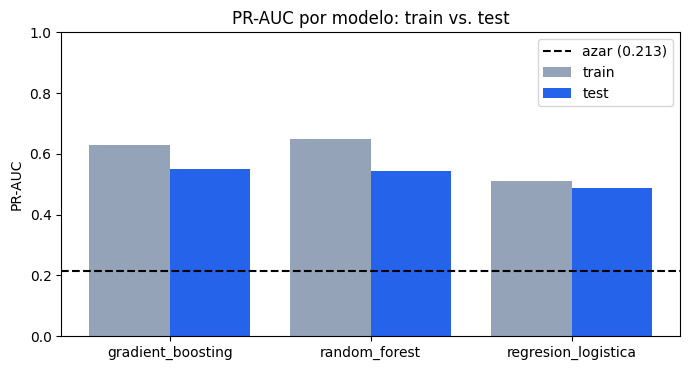

In [0]:
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(comparacion))
ax.bar(x - 0.2, comparacion["train_pr_auc"], width=0.4, label="train", color="#94a3b8")
ax.bar(x + 0.2, comparacion["pr_auc"], width=0.4, label="test", color="#2563eb")
ax.axhline(base_rate, color="black", ls="--", label=f"azar ({base_rate:.3f})")
ax.set_xticks(x, comparacion["modelo"])
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 1)
ax.set_title("PR-AUC por modelo: train vs. test")
ax.legend()
fig.tight_layout()
plt.show()

**Criterio de elección:** el mayor PR-AUC en test. Si dos modelos quedan a menos de 0,005 de distancia (empate práctico), se elige el de menor brecha entre train y test, porque es el que menos sobreajusta.

In [0]:
comparacion["brecha_train_test"] = comparacion["train_pr_auc"] - comparacion["pr_auc"]
candidatos = comparacion[comparacion["pr_auc"] >= comparacion["pr_auc"].max() - 0.005]
fila = candidatos.sort_values("brecha_train_test").iloc[0]
elegido, run_elegido = fila["modelo"], fila["run_id"]
scores = resultados[elegido]["scores_test"]
pipeline_elegido = resultados[elegido]["pipeline"]
display(comparacion[["modelo", "pr_auc", "train_pr_auc", "brecha_train_test"]].round(3))
print(f"Modelo elegido: {elegido} (PR-AUC test {fila['pr_auc']:.3f}, brecha {fila['brecha_train_test']:.3f}) · run_id {run_elegido}")

modelo,pr_auc,train_pr_auc,brecha_train_test
gradient_boosting,0.55,0.628,0.078
random_forest,0.544,0.648,0.104
regresion_logistica,0.487,0.511,0.023


Modelo elegido: gradient_boosting (PR-AUC test 0.550, brecha 0.078) · run_id 4e47b8d34a7d492baa8acb0f8af93d36


## 5. Lectura de negocio del modelo elegido

El modelo no dice "este cliente va a caer en mora": da una **probabilidad**. Lo que importa para el negocio es si esa probabilidad **ordena bien** a los clientes, de forma que el banco pueda concentrar sus acciones preventivas (contacto, refinanciación, ajuste de límite) en quienes tienen más riesgo.

### 5.1 Deciles de riesgo

Se ordenan los clientes de test del más riesgoso al menos riesgoso según el modelo y se dividen en 10 grupos iguales. Para cada decil:

- **tasa de mora:** qué porcentaje de ese grupo cayó en mora;
- **captura acumulada:** qué porcentaje del total de clientes en mora está entre los deciles 1 y ese;
- **lift:** cuántas veces más mora hay en ese grupo que en el promedio.

In [0]:
tabla = pd.DataFrame({"score": scores, "mora": y_test.values})
tabla["decil"] = pd.qcut(tabla["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
deciles = (tabla.groupby("decil", observed=True)
           .agg(clientes=("mora", "size"), en_mora=("mora", "sum"),
                score_min=("score", "min"), score_max=("score", "max"))
           .reset_index())
deciles["tasa_mora"] = deciles["en_mora"] / deciles["clientes"]
deciles["captura_acumulada"] = deciles["en_mora"].cumsum() / deciles["en_mora"].sum()
deciles["lift"] = deciles["tasa_mora"] / base_rate
display(deciles.round(3))

decil,clientes,en_mora,score_min,score_max,tasa_mora,captura_acumulada,lift
1,598,412,0.557,0.887,0.689,0.323,3.233
2,598,254,0.316,0.557,0.425,0.523,1.993
3,598,152,0.22,0.316,0.254,0.642,1.193
4,598,102,0.174,0.22,0.171,0.722,0.8
5,598,83,0.148,0.174,0.139,0.787,0.651
6,597,87,0.126,0.148,0.146,0.856,0.684
7,598,64,0.104,0.126,0.107,0.906,0.502
8,598,61,0.085,0.104,0.102,0.954,0.479
9,598,37,0.065,0.085,0.062,0.983,0.29
10,598,22,0.016,0.065,0.037,1.0,0.173


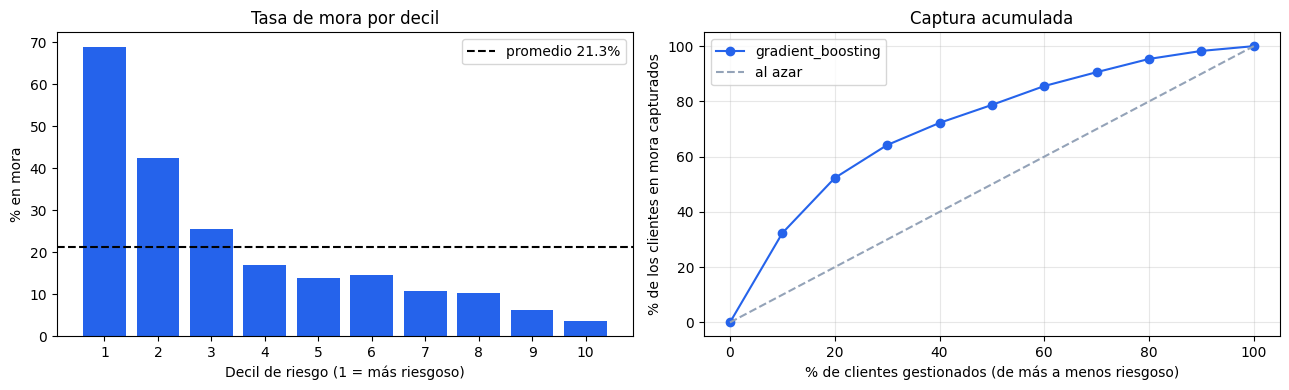

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(deciles["decil"].astype(str), deciles["tasa_mora"] * 100, color="#2563eb")
axes[0].axhline(base_rate * 100, color="black", ls="--", label=f"promedio {base_rate:.1%}")
axes[0].set_xlabel("Decil de riesgo (1 = más riesgoso)")
axes[0].set_ylabel("% en mora")
axes[0].set_title("Tasa de mora por decil")
axes[0].legend()

clientes_pct = np.arange(0, 11) * 10
captura_pct = np.concatenate([[0], deciles["captura_acumulada"].values * 100])
axes[1].plot(clientes_pct, captura_pct, marker="o", color="#2563eb", label=elegido)
axes[1].plot([0, 100], [0, 100], color="#94a3b8", ls="--", label="al azar")
axes[1].set_xlabel("% de clientes gestionados (de más a menos riesgoso)")
axes[1].set_ylabel("% de los clientes en mora capturados")
axes[1].set_title("Captura acumulada")
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.tight_layout()
fig_deciles = fig
plt.show()

### 5.2 Elección del umbral

El umbral decide a cuántos clientes se marca "en riesgo". Bajarlo detecta más clientes en mora (más **recall**) a cambio de más alertas falsas (menos **precision**). La elección depende de cuántos clientes puede gestionar el área de cobranzas y de cuánto cuesta cada error:

- **alerta falsa:** se contacta a un cliente que iba a pagar (costo bajo: una llamada o un recordatorio);
- **mora no detectada:** el banco no actúa a tiempo y la deuda se vuelve más difícil de recuperar (costo alto).

In [0]:
filas = []
y = y_test.values
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = scores >= umbral
    filas.append({"umbral": umbral,
                  "alertas": int(pred.sum()),
                  "% clientes alertados": pred.mean(),
                  "precision": precision_score(y, pred, zero_division=0),
                  "recall": recall_score(y, pred, zero_division=0),
                  "alertas falsas": int((pred & (y == 0)).sum()),
                  "moras no detectadas": int((~pred & (y == 1)).sum())})
umbrales = pd.DataFrame(filas)
display(umbrales.round(3))

umbral,alertas,% clientes alertados,precision,recall,alertas falsas,moras no detectadas
0.2,1993,0.333,0.433,0.677,1130,411
0.3,1288,0.215,0.54,0.546,593,579
0.4,892,0.149,0.62,0.434,339,721
0.5,681,0.114,0.664,0.355,229,822
0.6,537,0.09,0.704,0.297,159,896


### 5.3 Qué variables usa el modelo

**Importancia por permutación:** se desordena al azar una columna por vez y se mide cuánto cae el PR-AUC. Si al desordenarla el modelo empeora mucho, esa variable es importante. Se calcula sobre test.

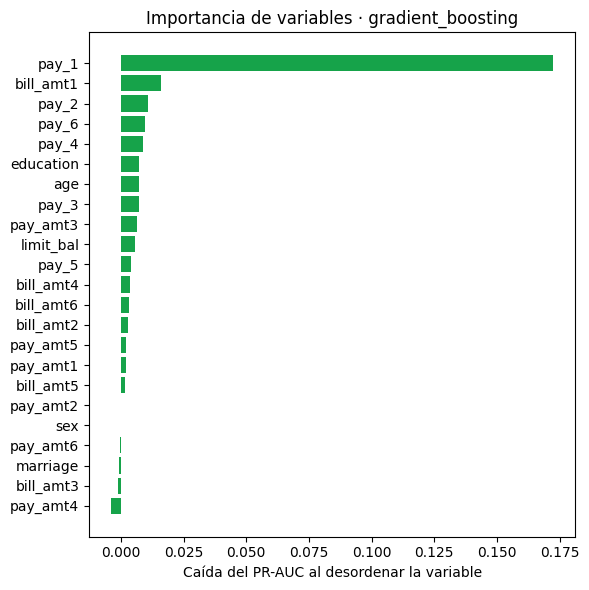

variable,importancia
pay_1,0.1724
bill_amt1,0.0158
pay_2,0.0108
pay_6,0.0098
pay_4,0.0088
education,0.0073
age,0.0072
pay_3,0.0071
pay_amt3,0.0066
limit_bal,0.0055


In [0]:
muestra = X_test.sample(2000, random_state=42)
perm = permutation_importance(pipeline_elegido, muestra, y_test.loc[muestra.index], scoring="average_precision",
                              n_repeats=5, random_state=42, n_jobs=1)
importancia = (pd.DataFrame({"variable": FEATURES, "importancia": perm.importances_mean})
               .sort_values("importancia", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(6, 6))
orden = importancia.iloc[::-1]
ax.barh(orden["variable"], orden["importancia"], color="#16a34a")
ax.set_xlabel("Caída del PR-AUC al desordenar la variable")
ax.set_title(f"Importancia de variables · {elegido}")
fig.tight_layout()
fig_importancia = fig
plt.show()
display(importancia.head(10).round(4))

### 5.4 Registrar el análisis en el run elegido

Las tablas y gráficos de esta sección se agregan como artefactos al run del modelo elegido, para que queden junto al modelo en MLflow.

In [0]:
with mlflow.start_run(run_id=run_elegido):
    mlflow.log_text(deciles.to_csv(index=False), "negocio/deciles_riesgo.csv")
    mlflow.log_text(umbrales.to_csv(index=False), "negocio/umbrales.csv")
    mlflow.log_text(importancia.to_csv(index=False), "negocio/importancia_variables.csv")
    mlflow.log_figure(fig_deciles, "negocio/deciles_riesgo.png")
    mlflow.log_figure(fig_importancia, "negocio/importancia_variables.png")
    mlflow.set_tag("elegido", "si")
print(f"Artefactos agregados al run {run_elegido} ({elegido})")

Artefactos agregados al run 4e47b8d34a7d492baa8acb0f8af93d36 (gradient_boosting)
